# Constrained planar five-link closed-chain mechanism

This notebook derives and simulates a planar mechanism made of five rigid links. Each link has center-of-mass coordinates `(x, y)` and orientation `theta`, so the generalized coordinate vector is `q in R^15`. Five revolute pins connect the links around one perimeter loop; link 4 is fixed horizontally. The grounded mechanism has 13 independent scalar constraints and two remaining degrees of freedom.

The notebook builds the holonomic residual `Phi(q)`, derives its Jacobian `J(q)`, forms the acceleration-level constrained dynamics, projects the initial state onto the constraint manifold, and integrates for ten seconds. It then visualizes and exports the trajectory. The time integrator is `solve_ivp` applied to an acceleration-level KKT solve with Baumgarte stabilization; this is a practical ODE treatment of the constrained equations, not a dedicated DAE solver.

Run the notebook from top to bottom. The code is broken into small cells so the geometry, constraint kinematics, dynamic solve, initial-state correction, time integration, visualization, and movie export can each be inspected independently.

In [91]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

np.set_printoptions(precision=5, suppress=True)

## Coordinates, energies, and pin constraints

For body `i`, the three generalized coordinates are its center-of-mass position and orientation:

$$q_i = [x_i, y_i, \theta_i]^T, \qquad q = [q_1^T, \ldots, q_5^T]^T \in \mathbb{R}^{15}.$$

The velocity and acceleration vectors use the same coordinate order:

$$\dot q = [\dot x_1,\dot y_1,\dot\theta_1,\ldots,\dot x_5,\dot y_5,\dot\theta_5]^T, \qquad
\ddot q = [\ddot x_1,\ddot y_1,\ddot\theta_1,\ldots,\ddot x_5,\ddot y_5,\ddot\theta_5]^T.$$

The SymPy components use the matching names `x1`, `y1`, `theta1`, `x_dot1`, `y_dot1`, `theta_dot1`, `x_ddot1`, `y_ddot1`, and `theta_ddot1` for each link. The Baumgarte tuning frequency is separately denoted by `omega` and is not a link angular velocity.

The model assumes each body is planar and rigid, and each body frame is attached at its center of mass. With constant mass and planar moment of inertia, the kinetic energy is

$$T = \frac12 \sum_i \left[m_i(\dot{x}_i^2+\dot{y}_i^2)+I_i\dot{\theta}_i^2\right]
= \frac12\dot q^T M\dot q,$$

where `M` is the constant diagonal matrix `diag(m1,m1,I1,...,m5,m5,I5)`. Taking vertical position `y` positive upward, gravity has potential energy `V = sum_i m_i g y_i`, so the generalized gravity force is `Q_g = -dV/dq`; its `y_i` entry is `-m_i g` and its other entries are zero. There are no velocity-dependent inertial terms in these center-of-mass coordinates.

A revolute (pin) joint joins one point fixed in body `a` to one point fixed in body `b`. Let `s_a` and `s_b` be those attachment coordinates expressed in their respective body frames. Define

$$A(\theta)=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix},
\qquad r_a(q)=p_a+A(\theta_a)s_a,$$

with `p_a = [x_a,y_a]^T` (and similarly for body `b`). A pin means the two world points coincide. It gives **two scalar holonomic constraints**:

$$\Phi_{ab}(q)=r_a(q)-r_b(q)=0.$$

Thus five pins give ten scalar equations; grounding a body pose adds three more. The number of equations alone does not establish mobility: inspect the rank of `J = dPhi/dq` at the configuration. The code below constructs each residual and its analytical Jacobian.

In [92]:
def rotation(theta):
    """Planar rotation matrix from a body frame to the world frame."""
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])


# S generates a 90-degree rotation, so d(A @ s)/dtheta = S @ A @ s.
S = np.array([[0.0, -1.0], [1.0, 0.0]])


class PinConstraintModel:
    """Rigid-body kinematics and holonomic pin/fixed-pose constraints."""

    def __init__(self, masses, inertias, joints, gravity=9.81, fixed_bodies=None):
        self.masses = np.asarray(masses, dtype=float)
        self.inertias = np.asarray(inertias, dtype=float)
        self.joints = joints
        self.n_bodies = len(self.masses)
        self.gravity = float(gravity)
        self.fixed_bodies = {
            int(body): np.asarray(pose, dtype=float).copy()
            for body, pose in (fixed_bodies or {}).items()
        }
        if self.inertias.shape != self.masses.shape:
            raise ValueError('masses and inertias must have the same length')
        if np.any(self.masses <= 0) or np.any(self.inertias <= 0):
            raise ValueError('masses and inertias must be positive')
        for body, pose in self.fixed_bodies.items():
            if not 0 <= body < self.n_bodies or pose.shape != (3,):
                raise ValueError('fixed bodies need a valid index and an (x, y, theta) pose')
        for body_a, body_b, point_a, point_b in joints:
            if body_a == body_b:
                raise ValueError('a pin must connect distinct bodies or a body and ground')
            for body in (body_a, body_b):
                if body != -1 and not 0 <= body < self.n_bodies:
                    raise ValueError(f'invalid body index: {body}')
            if body_a == -1 and body_b == -1:
                raise ValueError('a joint cannot connect ground to itself')

        # Each pin contributes two rows; fixing one planar pose contributes x, y, theta.
        self.pin_constraint_count = 2 * len(joints)
        self.n_constraints = self.pin_constraint_count + 3 * len(self.fixed_bodies)

        # Coordinates are ordered [x1,y1,theta1, x2,y2,theta2, ...].
        diagonal = np.column_stack((self.masses, self.masses, self.inertias)).ravel()
        self.mass_matrix = np.diag(diagonal)

    def point_offset(self, q, body, local_point):
        """Rotate a body-local attachment vector into world coordinates."""
        if body == -1:
            return np.asarray(local_point, dtype=float)
        theta = q[3 * body + 2]
        return rotation(theta) @ np.asarray(local_point, dtype=float)

    def constraints_and_jacobian(self, q):
        """Return Phi(q) and J(q) = dPhi/dq for pins and fixed bodies."""
        q = np.asarray(q, dtype=float)
        phi = np.zeros(self.n_constraints)
        jac = np.zeros((self.n_constraints, 3 * self.n_bodies))
        for joint_index, (body_a, body_b, local_a, local_b) in enumerate(self.joints):
            row = slice(2 * joint_index, 2 * joint_index + 2)
            difference = np.zeros(2)

            # A pin residual is world_point_a - world_point_b; the same signs apply to J.
            for body, local_point, sign in ((body_a, local_a, 1.0), (body_b, local_b, -1.0)):
                offset = self.point_offset(q, body, local_point)
                if body == -1:
                    difference += sign * offset
                    continue
                start = 3 * body
                difference += sign * (q[start:start + 2] + offset)
                jac[row, start:start + 2] += sign * np.eye(2)
                jac[row, start + 2] += sign * (S @ offset)
            phi[row] = difference

        # A fixed body's three residuals pin its CoM and orientation to the reference pose.
        for fixed_index, (body, fixed_pose) in enumerate(self.fixed_bodies.items()):
            start = 3 * body
            row_start = self.pin_constraint_count + 3 * fixed_index
            row = slice(row_start, row_start + 3)
            phi[row] = q[start:start + 3] - fixed_pose
            jac[row, start:start + 3] = np.eye(3)
        return phi, jac

    def jdot_qdot(self, q, qdot):
        """Return the quadratic-velocity term in the pin acceleration constraints."""
        bias = np.zeros(self.n_constraints)
        for joint_index, (body_a, body_b, local_a, local_b) in enumerate(self.joints):
            row = slice(2 * joint_index, 2 * joint_index + 2)
            for body, local_point, sign in ((body_a, local_a, 1.0), (body_b, local_b, -1.0)):
                if body == -1:
                    continue
                theta_dot = qdot[3 * body + 2]
                offset = self.point_offset(q, body, local_point)
                # The rotating offset contributes centripetal acceleration -theta_dot**2 * offset.
                bias[row] += sign * (-theta_dot**2 * offset)
        return bias

### Deriving the constraint Jacobian and acceleration equation

Write `S = [[0,-1],[1,0]]`. Since `dA/dtheta = S A`, the velocity of an attached point is

$$\dot r_i = \dot p_i + \dot\theta_i S A(\theta_i)s_i.$$

Differentiating the pin residual gives one two-row Jacobian block for each body:

$$J_i = \frac{\partial r_i}{\partial q_i}
= [\ I_2 \quad S A(\theta_i)s_i\ ],$$

with a positive sign for the first body in the joint and a negative sign for the second. This is the analytical `J = dPhi/dq` assembled in `constraints_and_jacobian`.

Differentiate `Phi(q)=0` with respect to time. The velocity-level constraint is

$$\dot\Phi = J(q)\dot q = 0.$$

Differentiate again. Because the Jacobian depends on configuration, it changes with time:

$$\ddot\Phi = J(q)\ddot q + \dot J(q,\dot q)\dot q = 0.$$

For one rotating attachment, its acceleration is

$$\ddot r_i = \ddot p_i + \ddot\theta_i S A s_i - \dot\theta_i^2 A s_i.$$

The last term is centripetal acceleration. Taking the signed difference of these terms across the pin joints gives `Jdot_qdot`; fixed-pose constraints have zero curvature term.

The Euler-Lagrange equations with constraint forces are

$$M\ddot q + J^T\lambda = Q, \qquad Q=-\frac{\partial V}{\partial q}.$$

Together with the acceleration constraints they form the saddle-point linear system solved at each RHS evaluation:

$$\begin{bmatrix}M&J^T\\J&0\end{bmatrix}
\begin{bmatrix}\ddot q\\\lambda\end{bmatrix}
= \begin{bmatrix}Q\\-\dot J\dot q\end{bmatrix}.$$

`lambda` contains the joint reaction forces (and the reactions that hold the fixed body). Its sign depends on the convention used to define `Phi`; here the pin residual is first attachment minus second attachment and the equations use `+J.T @ lambda`.

In [93]:
class PlanarSystem(PinConstraintModel):
    """Mass matrix, generalized forces, and constrained acceleration solve."""

    def generalized_forces(self, q, qdot, time):
        """Gravity generalized force; extend this method to add drives or loads."""
        forces = np.zeros(3 * self.n_bodies)
        forces[1::3] = -self.masses * self.gravity
        return forces

    def accelerations(self, q, qdot, time=0.0, zeta=1.0, omega=20.0):
        """Solve the stabilized saddle-point system for qddot and reactions."""
        phi, jac = self.constraints_and_jacobian(q)
        phi_dot = jac @ qdot
        rank = np.linalg.matrix_rank(jac)
        if rank < self.n_constraints:
            raise np.linalg.LinAlgError(
                f'constraint Jacobian rank {rank} is below {self.n_constraints}; '
                'constraints are dependent at this pose'
            )

        # Differentiate the Baumgarte error equation and place its correction in the constraint RHS.
        stabilization = 2.0 * zeta * omega * phi_dot + omega**2 * phi
        constraint_rhs = -self.jdot_qdot(q, qdot) - stabilization

        # Top block is M*qdd + J.T*lambda = Q; bottom block enforces Phi acceleration.
        kkt = np.block([
            [self.mass_matrix, jac.T],
            [jac, np.zeros((self.n_constraints, self.n_constraints))],
        ])
        rhs = np.concatenate((self.generalized_forces(q, qdot, time), constraint_rhs))
        solution = np.linalg.solve(kkt, rhs)
        split = 3 * self.n_bodies
        return solution[:split], solution[split:], jac, phi

### Projecting initial conditions onto the constraints

A numerical initial guess should satisfy both position and velocity constraints. The position projection uses the first-order correction

$$J(q_k)\,\Delta q = -\Phi(q_k), \qquad q_{k+1}=q_k+\Delta q.$$

Because the five-link model can have fewer independent rows than coordinates, `lstsq` selects a minimum-norm correction. This is iterated until the residual is small. The velocity projection similarly chooses a minimum-norm correction satisfying

$$J(q)\,\Delta\dot q=-J(q)\dot q.$$

These projections create consistent initial values; they are not being applied after each integration step here.

In [94]:
class ProjectedPlanarSystem(PlanarSystem):
    """Planar constrained model with least-squares initial-state projection."""

    def project_positions(self, q, tolerance=1e-11, max_iterations=20):
        q = np.asarray(q, dtype=float).copy()
        for _ in range(max_iterations):
            phi, jac = self.constraints_and_jacobian(q)
            if np.linalg.norm(phi, ord=np.inf) < tolerance:
                return q
            # Linearize Phi(q + dq) and take the minimum-norm correction J*dq = -Phi.
            correction, *_ = np.linalg.lstsq(jac, -phi, rcond=None)
            q += correction
        raise RuntimeError('position projection did not converge')

    def project_velocities(self, q, qdot):
        _, jac = self.constraints_and_jacobian(q)
        # Remove the velocity component that would violate the pins or fixed-body pose.
        correction, *_ = np.linalg.lstsq(jac, -(jac @ qdot), rcond=None)
        return qdot + correction

## Build and validate an example

The five pin joints connect the perimeter links into one closed loop. Link 4 (body index 3) is fixed at its initial CoM with angle zero, and its two pin attachments lie on its local x-axis, so it is horizontal. This leaves 13 independent constraints on 15 coordinates, or two degrees of freedom. The former link 1-to-3 diagonal pin is omitted because it would make the grounded assembly rigid. A small constraint-compatible initial angular velocity starts the mechanism moving.

In [95]:
body_count = 5

# Named numerical parameters feed the integrator; the symbolic cell uses m1..m5 and I1..I5.
m1_value, m2_value, m3_value, m4_value, m5_value = 1.2, 0.9, 1.1, 1.0, 0.8
I1_value, I2_value, I3_value, I4_value, I5_value = 0.30, 0.22, 0.28, 0.25, 0.18
mass_values = np.array([m1_value, m2_value, m3_value, m4_value, m5_value])
inertia_values = np.array([I1_value, I2_value, I3_value, I4_value, I5_value])

# Give each link a readable name; indices remain zero-based for the solver.
link_1, link_2, link_3, link_4, link_5 = range(body_count)
edge_list = [
    (link_1, link_2),
    (link_2, link_3),
    (link_3, link_4),
    (link_4, link_5),
    (link_5, link_1),  # Closing pin makes the five-link perimeter a loop.
]

# World coordinates of the five perimeter pins, named by the links they connect.
pin_12 = np.array([1.4, 0.8])
pin_23 = np.array([0.5, 1.4])
pin_34 = np.array([-0.5, -0.4])
pin_45 = np.array([0.5, -0.4])
pin_51 = np.array([-1.3, -0.9])
world_pin_points = np.array([pin_12, pin_23, pin_34, pin_45, pin_51])

### Constructing the closed-loop rod geometry

Each link is defined by its left and right pin points in the perimeter loop. Its numerical length is the distance between those pins, its CoM is their midpoint, and its body x-axis points from left to right. The numeric model therefore uses local endpoints `[-L_i/2, 0]` and `[+L_i/2, 0]`; the symbolic derivation below replaces each numeric length with a symbol `L_i`.

In [96]:
# Each link runs from its left pin to its right pin in the loop ordering.
body_endpoints = [
    (pin_51, pin_12),
    (pin_12, pin_23),
    (pin_23, pin_34),
    (pin_34, pin_45),
    (pin_45, pin_51),
]
link_length_values = np.array([
    np.linalg.norm(right_pin - left_pin)
    for left_pin, right_pin in body_endpoints
])
centers = np.array([
    0.5 * (left_pin + right_pin)
    for left_pin, right_pin in body_endpoints
])
angles = np.array([
    np.arctan2((right_pin - left_pin)[1], (right_pin - left_pin)[0])
    for left_pin, right_pin in body_endpoints
])
assert np.isclose(angles[link_4], 0.0)

# CoM coordinates stay at each link midpoint; its orientation follows the link axis.
q_guess = np.zeros(3 * body_count)
for body in range(body_count):
    q_guess[3 * body:3 * body + 3] = [*centers[body], angles[body]]

For each pin pair, the numeric model uses the local rod endpoints `[-L_i/2, 0]` and `[+L_i/2, 0]` in link `i`'s frame. The symbolic model keeps each `L_i` as a SymPy symbol; numeric lengths are inserted only to simulate this example and to validate the equations.

In [97]:
joints = []
for body_a, body_b in edge_list:
    # Every link's body x-axis follows its pin-to-pin line; the CoM is at the midpoint.
    local_a = np.array([0.5 * link_length_values[body_a], 0.0])
    local_b = np.array([-0.5 * link_length_values[body_b], 0.0])
    joints.append((body_a, body_b, local_a, local_b))

fixed_link_index = link_4
system = ProjectedPlanarSystem(
    mass_values,
    inertia_values,
    joints,
    fixed_bodies={fixed_link_index: q_guess[3 * fixed_link_index:3 * fixed_link_index + 3]},
)
q0 = system.project_positions(q_guess)

# Try rotating link 1, then project the trial velocity so J*qdot = 0 exactly.
qdot_guess = np.zeros_like(q0)
qdot_guess[2] = 0.25
qdot0 = system.project_velocities(q0, qdot_guess)

In [98]:
phi0, jac0 = system.constraints_and_jacobian(q0)
constraint_rank = np.linalg.matrix_rank(jac0)
# Local mobility is coordinates minus independent constraint rank (15 - 13 = 2 here).
freedom_count = 3 * body_count - constraint_rank
assert len(joints) == 5
assert system.pin_constraint_count == 10
assert system.n_constraints == 13
assert constraint_rank == 13
assert freedom_count == 2
assert np.linalg.norm(phi0, ord=np.inf) < 1e-10
assert np.linalg.norm(jac0 @ qdot0, ord=np.inf) < 1e-10
assert np.isclose(q0[11], 0.0)

print(f'Pin joints: {len(joints)} (outer closed loop)')
print(f'Independent scalar constraints: {constraint_rank}; remaining DOF: {freedom_count}')
print(f'Initial max |Phi|: {np.linalg.norm(phi0, ord=np.inf):.3e}')
print(f'Initial max |J qdot|: {np.linalg.norm(jac0 @ qdot0, ord=np.inf):.3e}')

Pin joints: 5 (outer closed loop)
Independent scalar constraints: 13; remaining DOF: 2
Initial max |Phi|: 4.441e-16
Initial max |J qdot|: 4.718e-16


### Check the acceleration-level equations

At the initial consistent state, solve once for acceleration and constraint reactions. The following residual checks independently verify the force-balance top block and the stabilized acceleration-constraint bottom block of the KKT system.

In [99]:
qdd0, lambda0, jac0, phi0 = system.accelerations(q0, qdot0)
phi_dot0 = jac0 @ qdot0

# Residual of J*qdd + Jdot*qdot + Baumgarte terms = 0.
acceleration_residual = (
    jac0 @ qdd0 + system.jdot_qdot(q0, qdot0)
    + 2.0 * 20.0 * phi_dot0 + 20.0**2 * phi0
)

# Residual of the generalized force balance M*qdd + J.T*lambda = Q.
force_residual = (
    system.mass_matrix @ qdd0 + jac0.T @ lambda0
    - system.generalized_forces(q0, qdot0, 0.0)
)
assert np.linalg.norm(acceleration_residual, ord=np.inf) < 1e-9
assert np.linalg.norm(force_residual, ord=np.inf) < 1e-9
print(f'Max KKT force-balance residual: {np.linalg.norm(force_residual, ord=np.inf):.3e}')
print(f'Max stabilized acceleration residual: {np.linalg.norm(acceleration_residual, ord=np.inf):.3e}')

Max KKT force-balance residual: 4.663e-15
Max stabilized acceleration residual: 7.834e-15


## Symbolic derivation for this mechanism

The following cells derive the configured five-link model with symbolic masses, inertias, gravity, and pin-to-pin link lengths: `masses = np.array([m1, ..., m5])`, `inertias = np.array([I1, ..., I5])`, and `link_lengths = np.array([L1, ..., L5])`. Each symbolic link is centered at its CoM with local pin endpoints `[-L_i/2, 0]` and `[+L_i/2, 0]`. Numerical link lengths are used only by the integrator and final cross-check.

The holonomic residuals and their Jacobian therefore depend explicitly on `L1,...,L5`, rather than on long decimal-derived pin-offset coefficients. The symbolic KKT equations also retain `m_i`, `I_i`, and `g`; numerical values are substituted only in the final cross-check and integration model.

In [100]:
import sympy as sp
from IPython.display import Markdown, display


def symbolic_constant(value):
    """Keep SymPy expressions symbolic and rationalize configured numeric geometry."""
    if isinstance(value, sp.Basic):
        return value
    return sp.Rational(f'{float(value):.12g}')


# Keep physical parameters symbolic in the equations; concrete values are separate for simulation.
m1, m2, m3, m4, m5 = sp.symbols('m1:6', positive=True)
I1, I2, I3, I4, I5 = sp.symbols('I1:6', positive=True)
L1, L2, L3, L4, L5 = sp.symbols('L1:6', positive=True)
g_sym = sp.symbols('g', positive=True)
masses = np.array([m1, m2, m3, m4, m5], dtype=object)
inertias = np.array([I1, I2, I3, I4, I5], dtype=object)
link_lengths = np.array([L1, L2, L3, L4, L5], dtype=object)
mass_symbols = tuple(masses)
inertia_symbols = tuple(inertias)
length_symbols = tuple(link_lengths)

# Symbolic pins join the right end of each link to the left end of the next link.
symbolic_joints = []
for body_a, body_b in edge_list:
    local_a = sp.Matrix([link_lengths[body_a] / 2, 0])
    local_b = sp.Matrix([-link_lengths[body_b] / 2, 0])
    symbolic_joints.append((body_a, body_b, local_a, local_b))

# Scalar symbols follow the same x, y, theta ordering as q, qdot, and qddot.
q_symbols = []
qdot_symbols = []
qddot_symbols = []
for body in range(body_count):
    body_index = body + 1
    q_symbols.extend(sp.symbols(f'x{body_index} y{body_index} theta{body_index}'))
    qdot_symbols.extend(sp.symbols(f'x_dot{body_index} y_dot{body_index} theta_dot{body_index}'))
    qddot_symbols.extend(sp.symbols(f'x_ddot{body_index} y_ddot{body_index} theta_ddot{body_index}'))
q_sym = sp.Matrix(q_symbols)
qdot_sym = sp.Matrix(qdot_symbols)
qddot_sym = sp.Matrix(qddot_symbols)


def symbolic_point(q_vector, body, local_point):
    if body == -1:
        return sp.Matrix([symbolic_constant(local_point[0]), symbolic_constant(local_point[1])])
    start = 3 * body
    theta = q_vector[start + 2]
    local_x = symbolic_constant(local_point[0])
    local_y = symbolic_constant(local_point[1])
    body_to_world = sp.Matrix([
        [sp.cos(theta), -sp.sin(theta)],
        [sp.sin(theta), sp.cos(theta)],
    ])
    return q_vector[start:start + 2, :] + body_to_world * sp.Matrix([local_x, local_y])


# Each pin contributes x- and y-coincidence equations; fixed link 4 adds x, y, theta.
phi_entries = []
for body_a, body_b, local_a, local_b in symbolic_joints:
    phi_entries.extend(symbolic_point(q_sym, body_a, local_a) - symbolic_point(q_sym, body_b, local_b))
for fixed_body, fixed_pose in system.fixed_bodies.items():
    start = 3 * fixed_body
    phi_entries.extend(q_sym[start:start + 3, :] - sp.Matrix([
        symbolic_constant(component) for component in fixed_pose
    ]))
phi_sym = sp.Matrix(phi_entries).applyfunc(sp.trigsimp)
jac_sym = phi_sym.jacobian(q_sym).applyfunc(sp.trigsimp)
assert set(length_symbols).issubset(phi_sym.free_symbols)

# Assemble symbolic M, T, and V with the user-readable parameter arrays above.
mass_diagonal_sym = []
for body in range(body_count):
    mass_diagonal_sym.extend([masses[body], masses[body], inertias[body]])
mass_sym = sp.diag(*mass_diagonal_sym)
kinetic_energy_sym = sum(
    sp.Rational(1, 2) * masses[body] * (qdot_sym[3 * body]**2 + qdot_sym[3 * body + 1]**2)
    + sp.Rational(1, 2) * inertias[body] * qdot_sym[3 * body + 2]**2
    for body in range(body_count)
)
potential_energy_sym = sum(
    masses[body] * g_sym * q_sym[3 * body + 1]
    for body in range(body_count)
)
generalized_force_sym = -sp.Matrix([sp.diff(potential_energy_sym, coordinate) for coordinate in q_sym])

print(f'Symbolic coordinates: {len(q_symbols)}; symbolic link lengths: {list(link_lengths)}')
print(f'Pin equations: {system.pin_constraint_count}; fixed-pose equations: {3 * len(system.fixed_bodies)}')
display(sp.Eq(sp.Symbol('T'), kinetic_energy_sym))
display(sp.Eq(sp.Symbol('V'), potential_energy_sym))
display(Markdown('**Symbolic link lengths:**'))
display(sp.Matrix(link_lengths))
display(Markdown('**Holonomic residual vector Phi(q):**'))
display(phi_sym)
display(Markdown('**Constraint Jacobian J(q) = dPhi/dq:**'))
display(jac_sym)
display(Markdown('**Generalized force vector Q = -dV/dq:**'))
display(generalized_force_sym)

Symbolic coordinates: 15; symbolic link lengths: [L1, L2, L3, L4, L5]
Pin equations: 10; fixed-pose equations: 3


Eq(T, I1*theta_dot1**2/2 + I2*theta_dot2**2/2 + I3*theta_dot3**2/2 + I4*theta_dot4**2/2 + I5*theta_dot5**2/2 + m1*(x_dot1**2 + y_dot1**2)/2 + m2*(x_dot2**2 + y_dot2**2)/2 + m3*(x_dot3**2 + y_dot3**2)/2 + m4*(x_dot4**2 + y_dot4**2)/2 + m5*(x_dot5**2 + y_dot5**2)/2)

Eq(V, g*m1*y1 + g*m2*y2 + g*m3*y3 + g*m4*y4 + g*m5*y5)

**Symbolic link lengths:**

Matrix([
[L1],
[L2],
[L3],
[L4],
[L5]])

...

Matrix([
[L1*cos(theta1)/2 + L2*cos(theta2)/2 + x1 - x2],
[L1*sin(theta1)/2 + L2*sin(theta2)/2 + y1 - y2],
[L2*cos(theta2)/2 + L3*cos(theta3)/2 + x2 - x3],
[L2*sin(theta2)/2 + L3*sin(theta3)/2 + y2 - y3],
[L3*cos(theta3)/2 + L4*cos(theta4)/2 + x3 - x4],
[L3*sin(theta3)/2 + L4*sin(theta4)/2 + y3 - y4],
[L4*cos(theta4)/2 + L5*cos(theta5)/2 + x4 - x5],
[L4*sin(theta4)/2 + L5*sin(theta5)/2 + y4 - y5],
[L1*cos(theta1)/2 + L5*cos(theta5)/2 - x1 + x5],
[L1*sin(theta1)/2 + L5*sin(theta5)/2 - y1 + y5],
[                                           x4],
[                                     y4 + 2/5],
[                                       theta4]])

**Constraint Jacobian J(q) = dPhi/dq:**

Matrix([
[ 1,  0, -L1*sin(theta1)/2, -1,  0, -L2*sin(theta2)/2,  0,  0,                 0,  0,  0,                 0,  0,  0,                 0],
[ 0,  1,  L1*cos(theta1)/2,  0, -1,  L2*cos(theta2)/2,  0,  0,                 0,  0,  0,                 0,  0,  0,                 0],
[ 0,  0,                 0,  1,  0, -L2*sin(theta2)/2, -1,  0, -L3*sin(theta3)/2,  0,  0,                 0,  0,  0,                 0],
[ 0,  0,                 0,  0,  1,  L2*cos(theta2)/2,  0, -1,  L3*cos(theta3)/2,  0,  0,                 0,  0,  0,                 0],
[ 0,  0,                 0,  0,  0,                 0,  1,  0, -L3*sin(theta3)/2, -1,  0, -L4*sin(theta4)/2,  0,  0,                 0],
[ 0,  0,                 0,  0,  0,                 0,  0,  1,  L3*cos(theta3)/2,  0, -1,  L4*cos(theta4)/2,  0,  0,                 0],
[ 0,  0,                 0,  0,  0,                 0,  0,  0,                 0,  1,  0, -L4*sin(theta4)/2, -1,  0, -L5*sin(theta5)/2],
[ 0,  0,                 0,  0, 

**Generalized force vector Q = -dV/dq:**

Matrix([
[    0],
[-g*m1],
[    0],
[    0],
[-g*m2],
[    0],
[    0],
[-g*m3],
[    0],
[    0],
[-g*m4],
[    0],
[    0],
[-g*m5],
[    0]])

In [101]:
symbolic_outputs = [
    kinetic_energy_sym,
    potential_energy_sym,
    phi_sym,
    jac_sym,
    mass_sym,
    generalized_force_sym,
    *link_lengths,
]


def contains_float_coefficient(expression):
    entries = expression if isinstance(expression, sp.MatrixBase) else [expression]
    return any(entry.has(sp.Float) for entry in entries)


float_coefficients = [expression for expression in symbolic_outputs if contains_float_coefficient(expression)]
assert not float_coefficients
assert set(length_symbols).issubset(phi_sym.free_symbols)
assert set(length_symbols).issubset(jac_sym.free_symbols)
print('Exact-symbolic check passed: Phi, J, M, T, V, Q, and L1..L5 contain no SymPy Float coefficients.')

Exact-symbolic check passed: Phi, J, M, T, V, Q, and L1..L5 contain no SymPy Float coefficients.


### Ideal acceleration equations and numerical stabilization

Differentiating `Phi_dot = J*qdot` gives the ideal acceleration constraint `J*qddot + Jdot*qdot = 0`. The symbolic KKT equations displayed below use this ideal form and contain no Baumgarte gains.

The numerical `solve_ivp` demonstration optionally controls constraint drift with Baumgarte stabilization. Its acceleration residual is `J*qddot + Jdot*qdot + 2*zeta*omega_B*J*qdot + omega_B**2*Phi`; the gains `zeta` and `omega_B` belong to that numerical stabilization, not to the ideal mechanism equations. The following code defines 13 multipliers in row order: two reactions for each pin, followed by the three reactions that ground link 4.

In [112]:
# Differentiate Phi_dot = J(q)*qdot to get the ideal acceleration-level constraint.
phi_dot_sym = jac_sym * qdot_sym
jdot_qdot_sym = (phi_dot_sym.jacobian(q_sym) * qdot_sym).applyfunc(sp.trigsimp)
ideal_acceleration_constraint_sym = jac_sym * qddot_sym + jdot_qdot_sym

# Keep Baumgarte gains symbolic for a separate model of the numerical drift correction.
baumgarte_zeta_sym, baumgarte_omega_sym = sp.symbols('zeta_B omega_B', positive=True)
stabilized_acceleration_constraint_sym = (
    ideal_acceleration_constraint_sym
    + 2 * baumgarte_zeta_sym * baumgarte_omega_sym * phi_dot_sym
    + baumgarte_omega_sym**2 * phi_sym
)

lambda_symbols = sp.symbols('lambda_1:14')
lambda_sym = sp.Matrix(lambda_symbols)
dynamic_residual_sym = mass_sym * qddot_sym + jac_sym.T * lambda_sym - generalized_force_sym

# The displayed KKT system is the ideal DAE acceleration equation, without Baumgarte gains.
kkt_matrix_sym = sp.BlockMatrix([
    [mass_sym, jac_sym.T],
    [jac_sym, sp.zeros(system.n_constraints, system.n_constraints)],
]).as_explicit()
kkt_unknown_sym = qddot_sym.col_join(lambda_sym)
kkt_rhs_sym = generalized_force_sym.col_join(-jdot_qdot_sym)
kkt_residual_sym = kkt_matrix_sym * kkt_unknown_sym - kkt_rhs_sym

assert kkt_matrix_sym.shape == (28, 28)
assert kkt_unknown_sym.shape == (28, 1)
assert kkt_rhs_sym.shape == (28, 1)
assert set(length_symbols).issubset(ideal_acceleration_constraint_sym.free_symbols)
assert set(length_symbols).issubset(stabilized_acceleration_constraint_sym.free_symbols)
assert set(mass_symbols).issubset(dynamic_residual_sym.free_symbols)
assert set(inertia_symbols).issubset(dynamic_residual_sym.free_symbols)
assert g_sym in generalized_force_sym.free_symbols

print(f'Ideal KKT system dimensions: {kkt_matrix_sym.rows} equations x {kkt_matrix_sym.cols} unknowns')
print('Symbolic check passed: L_i, m_i, I_i, g, zeta_B, and omega_B remain symbolic.')
display(Markdown('**15 generalized force-balance equations; each residual equals zero:**'))
display(dynamic_residual_sym)
display(Markdown('**13 ideal acceleration constraints: J*qddot + Jdot*qdot = 0:**'))
display(ideal_acceleration_constraint_sym)

Ideal KKT system dimensions: 28 equations x 28 unknowns
Symbolic check passed: L_i, m_i, I_i, g, zeta_B, and omega_B remain symbolic.


**15 generalized force-balance equations; each residual equals zero:**

Matrix([
[                                                                                                          lambda_1 - lambda_9 + m1*x_ddot1],
[                                                                                                  g*m1 - lambda_10 + lambda_2 + m1*y_ddot1],
[           I1*theta_ddot1 - L1*lambda_1*sin(theta1)/2 + L1*lambda_10*cos(theta1)/2 + L1*lambda_2*cos(theta1)/2 - L1*lambda_9*sin(theta1)/2],
[                                                                                                         -lambda_1 + lambda_3 + m2*x_ddot2],
[                                                                                                   g*m2 - lambda_2 + lambda_4 + m2*y_ddot2],
[            I2*theta_ddot2 - L2*lambda_1*sin(theta2)/2 + L2*lambda_2*cos(theta2)/2 - L2*lambda_3*sin(theta2)/2 + L2*lambda_4*cos(theta2)/2],
[                                                                                                         -lambda_3 + lambda_5 + m3*x_ddot3

**13 ideal acceleration constraints: J*qddot + Jdot*qdot = 0:**

Matrix([
[-L1*theta_ddot1*sin(theta1)/2 - L1*theta_dot1**2*cos(theta1)/2 - L2*theta_ddot2*sin(theta2)/2 - L2*theta_dot2**2*cos(theta2)/2 + x_ddot1 - x_ddot2],
[ L1*theta_ddot1*cos(theta1)/2 - L1*theta_dot1**2*sin(theta1)/2 + L2*theta_ddot2*cos(theta2)/2 - L2*theta_dot2**2*sin(theta2)/2 + y_ddot1 - y_ddot2],
[-L2*theta_ddot2*sin(theta2)/2 - L2*theta_dot2**2*cos(theta2)/2 - L3*theta_ddot3*sin(theta3)/2 - L3*theta_dot3**2*cos(theta3)/2 + x_ddot2 - x_ddot3],
[ L2*theta_ddot2*cos(theta2)/2 - L2*theta_dot2**2*sin(theta2)/2 + L3*theta_ddot3*cos(theta3)/2 - L3*theta_dot3**2*sin(theta3)/2 + y_ddot2 - y_ddot3],
[-L3*theta_ddot3*sin(theta3)/2 - L3*theta_dot3**2*cos(theta3)/2 - L4*theta_ddot4*sin(theta4)/2 - L4*theta_dot4**2*cos(theta4)/2 + x_ddot3 - x_ddot4],
[ L3*theta_ddot3*cos(theta3)/2 - L3*theta_dot3**2*sin(theta3)/2 + L4*theta_ddot4*cos(theta4)/2 - L4*theta_dot4**2*sin(theta4)/2 + y_ddot3 - y_ddot4],
[-L4*theta_ddot4*sin(theta4)/2 - L4*theta_dot4**2*cos(theta4)/2 - L5*theta_ddot5*sin(theta5

In [113]:
length_dependent_equations = [
    phi_sym,
    jac_sym,
    dynamic_residual_sym,
    ideal_acceleration_constraint_sym,
    stabilized_acceleration_constraint_sym,
    kkt_matrix_sym,
    kkt_rhs_sym,
]
for equation in length_dependent_equations:
    assert set(length_symbols).issubset(equation.free_symbols)
    entries = equation if isinstance(equation, sp.MatrixBase) else [equation]
    assert not any(entry.has(sp.Float) for entry in entries)

assert baumgarte_zeta_sym in stabilized_acceleration_constraint_sym.free_symbols
assert baumgarte_omega_sym in stabilized_acceleration_constraint_sym.free_symbols
assert baumgarte_omega_sym not in ideal_acceleration_constraint_sym.free_symbols
print('Exact-symbolic check passed: L_i remain exact; ideal equations are gain-free and Baumgarte gains are symbolic only in the stabilized form.')

Exact-symbolic check passed: L_i remain exact; ideal equations are gain-free and Baumgarte gains are symbolic only in the stabilized form.


### Cross-check symbolic expressions against the numerical model

Evaluate the symbolic residuals at the projected initial state and compare them with the existing NumPy implementation. Agreement verifies that the symbolic derivation uses the same attachment signs, fixed-link equations, gravity convention, and centripetal terms as the integrator.

In [114]:
substitutions = dict(zip(q_symbols, q0))
substitutions.update(zip(qdot_symbols, qdot0))
substitutions.update(zip(qddot_symbols, qdd0))
substitutions.update(zip(lambda_symbols, lambda0))
# Substitute numeric model values only to compare symbolic mechanics against the integrator.
substitutions.update(zip(mass_symbols, mass_values))
substitutions.update(zip(inertia_symbols, inertia_values))
substitutions.update(zip(length_symbols, link_length_values))
substitutions[g_sym] = system.gravity

# Evaluate symbolic kinematics and ideal acceleration terms at the same state as the numeric model.
phi_symbolic_value = np.asarray(phi_sym.subs(substitutions).evalf(), dtype=float).reshape(-1)
jac_symbolic_value = np.asarray(jac_sym.subs(substitutions).evalf(), dtype=float)
bias_symbolic_value = np.asarray(jdot_qdot_sym.subs(substitutions).evalf(), dtype=float).reshape(-1)
dynamic_residual_value = np.asarray(dynamic_residual_sym.subs(substitutions).evalf(), dtype=float).reshape(-1)
ideal_acceleration_residual_value = np.asarray(
    ideal_acceleration_constraint_sym.subs(substitutions).evalf(), dtype=float
).reshape(-1)

phi_numeric_value, jac_numeric_value = system.constraints_and_jacobian(q0)
bias_numeric_value = system.jdot_qdot(q0, qdot0)
assert np.allclose(phi_symbolic_value, phi_numeric_value, atol=2e-10, rtol=0.0)
assert np.allclose(jac_symbolic_value, jac_numeric_value, atol=2e-10, rtol=0.0)
assert np.allclose(bias_symbolic_value, bias_numeric_value, atol=2e-10, rtol=0.0)
assert np.linalg.norm(dynamic_residual_value, ord=np.inf) < 1e-9
assert np.allclose(ideal_acceleration_residual_value, -40.0 * (jac0 @ qdot0) - 400.0 * phi0, atol=1e-9, rtol=0.0)
print(f'Numeric link lengths used only for validation: {link_length_values}')
print(f'Max symbolic-vs-numeric Phi difference: {np.max(np.abs(phi_symbolic_value - phi_numeric_value)):.3e}')
print(f'Max symbolic-vs-numeric J difference: {np.max(np.abs(jac_symbolic_value - jac_numeric_value)):.3e}')
print(f'Max symbolic-vs-numeric Jdot*qdot difference: {np.max(np.abs(bias_symbolic_value - bias_numeric_value)):.3e}')
print(f'Max symbolic KKT force residual: {np.linalg.norm(dynamic_residual_value, ord=np.inf):.3e}')
print(f'Initial ideal acceleration residual norm: {np.linalg.norm(ideal_acceleration_residual_value, ord=np.inf):.3e}')
print('Ideal residual differs from zero here only by the numerical integrator Baumgarte correction.')

Numeric link lengths used only for validation: [3.19061 1.08167 2.05913 1.      1.86815]
Max symbolic-vs-numeric Phi difference: 3.331e-16
Max symbolic-vs-numeric J difference: 2.220e-16
Max symbolic-vs-numeric Jdot*qdot difference: 4.337e-19
Max symbolic KKT force residual: 4.663e-15
Initial ideal acceleration residual norm: 1.674e-13
Ideal residual differs from zero here only by the numerical integrator Baumgarte correction.


## From constrained equations to a time integrator

The Euler-Lagrange equations are differential equations for the bodies coupled to algebraic equations `Phi(q)=0`. Written as a first-order system with unknown reactions, the ideal model is a differential-algebraic equation (DAE):

$$M\ddot q + J^T\lambda = Q, \qquad \Phi(q)=0.$$

The constraint must remain satisfied at position, velocity, and acceleration levels. At each evaluation of the right-hand side, the code solves the acceleration-level KKT system for both `qddot` and the reaction multipliers `lambda`. It then returns only the first-order state derivative for `y = [q, qdot]`:

$$\dot y = [\dot q,\ddot q].$$

In exact arithmetic, acceleration consistency alone does not remove numerical drift in `Phi` and `J qdot`. Here we use **Baumgarte stabilization**, replacing the zero acceleration residual with the damped error equation

$$\ddot\Phi+2\zeta\omega\dot\Phi+\omega^2\Phi=0,$$

which gives the KKT lower-right-hand-side term `-Jdot_qdot - 2*zeta*omega*(J qdot) - omega**2*Phi`. `zeta` is a damping ratio and `omega` sets the correction timescale. Large values can make the integration stiff, so they should be chosen with care.

`solve_ivp` is therefore integrating an **ODE produced by an acceleration-level constrained solve**, not solving the full DAE with a dedicated DAE method. Omitting its `method` argument selects SciPy's default RK45 scheme. In this notebook, `rtol=1e-8`, `atol=1e-10`, and `max_step=0.01` control the adaptive integration; `t_eval` requests 2,001 saved output times and does not force the solver to step at every one of them. Initial position and velocity are projected onto the constraint manifold once, before integration. This is a practical teaching/demo method, not the most robust choice for long, stiff, or contact-rich simulations; dedicated DAE solvers or stepwise constraint projection are alternatives.

In [115]:
def state_derivative(time, state):
    """Map state [q, qdot] to [qdot, qddot] after a constrained solve."""
    coordinate_count = 3 * body_count
    # Split the first-order state into generalized positions and velocities.
    q = state[:coordinate_count]
    qdot = state[coordinate_count:]
    qddot, _, _, _ = system.accelerations(q, qdot, time)
    return np.concatenate((qdot, qddot))


simulation_duration = 10.0
output_count = 2001
# t_eval controls saved samples; RK45 chooses its own internal adaptive steps.
time_samples = np.linspace(0.0, simulation_duration, output_count)
state0 = np.concatenate((q0, qdot0))
solution = solve_ivp(
    state_derivative,
    (0.0, simulation_duration),
    state0,
    t_eval=time_samples,
    rtol=1e-8,
    atol=1e-10,
    max_step=0.01,
)
if not solution.success:
    raise RuntimeError(solution.message)

# Extract the position history and verify closure and the grounded pose at the final time.
coordinate_count = 3 * body_count
q_history = solution.y[:coordinate_count, :]
q_final = q_history[:, -1]
phi_final, _ = system.constraints_and_jacobian(q_final)
constraint_error = np.linalg.norm(phi_final, ord=np.inf)
link4_pose_error = np.linalg.norm(q_final[9:12] - q0[9:12], ord=np.inf)
body_motion = np.linalg.norm(q_final[:9] - q0[:9])
assert np.isclose(solution.t[-1], simulation_duration)
assert constraint_error < 1e-6
assert link4_pose_error < 1e-9
assert body_motion > 1e-4
print(f'Integration successful: {solution.success}; RHS evaluations: {solution.nfev}')
print(f'Simulated duration: {solution.t[-1]:.2f} s; saved samples: {solution.t.size}')
print(f'Final max |Phi|: {constraint_error:.3e}; link 4 pose error: {link4_pose_error:.3e}')
print(f'Combined displacement of moving links: {body_motion:.6f}')

Integration successful: True; RHS evaluations: 13154
Simulated duration: 10.00 s; saved samples: 2001
Final max |Phi|: 9.353e-11; link 4 pose error: 3.359e-19
Combined displacement of moving links: 7.818264


## Visualizing body geometry

For drawing, each link is represented by the polygon formed by its pin attachment points in the current configuration. These outlines are a visualization aid; the dynamics model treats each body as a rigid body with its full mass and inertia, not as a deformable polygon.

In [106]:
def body_attachment_points(model, q, body):
    points = []
    for body_a, body_b, local_a, local_b in model.joints:
        if body_a == body:
            points.append(q[3 * body:3 * body + 2] + model.point_offset(q, body, local_a))
        if body_b == body:
            points.append(q[3 * body:3 * body + 2] + model.point_offset(q, body, local_b))
    return np.asarray(points)


def draw_configuration(ax, q, title):
    pose = q.reshape(body_count, 3)
    all_pin_points = []
    for body in range(body_count):
        pin_points = body_attachment_points(system, q, body)
        all_pin_points.extend(pin_points)
        center = pose[body, :2]

        # Sort the attachment points around the CoM to draw a simple visual outline.
        # This polygon is only a display proxy; dynamics use the full rigid-body mass properties.
        angles_from_center = np.arctan2(
            pin_points[:, 1] - center[1], pin_points[:, 0] - center[0]
        )
        outline = pin_points[np.argsort(angles_from_center)]
        if len(outline) > 2:
            outline = np.vstack((outline, outline[0]))
        ax.plot(outline[:, 0], outline[:, 1], color=f'C{body}', linewidth=2.5,
                label=f'Link {body + 1}')
        ax.scatter(*center, color=f'C{body}', s=28, zorder=3)
        ax.annotate(str(body + 1), center, xytext=(5, 5), textcoords='offset points', fontsize=9)
    all_pin_points = np.asarray(all_pin_points)
    ax.scatter(all_pin_points[:, 0], all_pin_points[:, 1], marker='s', color='black', s=22,
               label='Pin locations', zorder=4)
    fixed_center = q[9:11]
    ax.plot(fixed_center[0], fixed_center[1], marker='x', color='black', markersize=9,
            label='Fixed link CoM')
    ax.set_title(title)
    ax.set_xlabel('x [m]')
    ax.set_ylabel('y [m]')
    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, alpha=0.25)

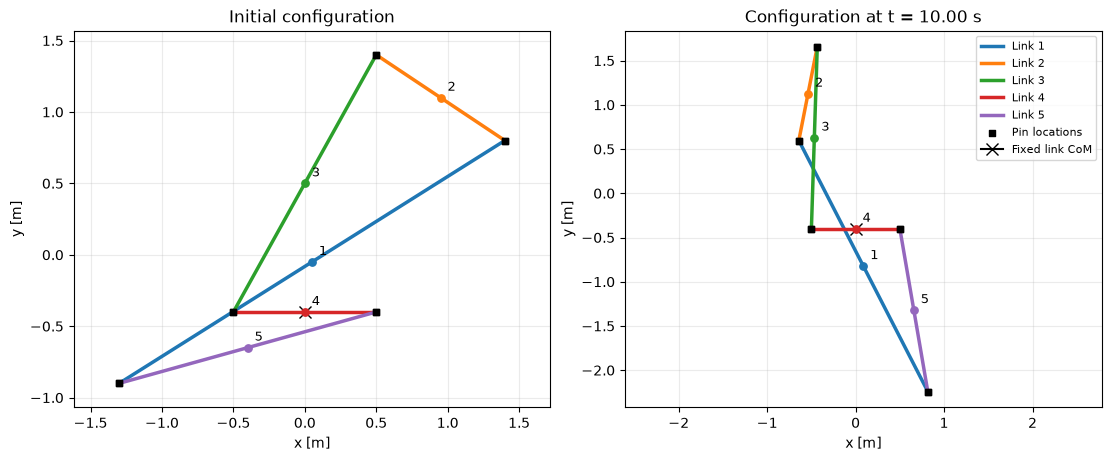

In [107]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
draw_configuration(axes[0], q0, 'Initial configuration')
draw_configuration(axes[1], q_final, f'Configuration at t = {solution.t[-1]:.2f} s')
axes[1].legend(loc='best', fontsize=8)
plt.show()

In [108]:
from pathlib import Path
from matplotlib.animation import FuncAnimation, PillowWriter
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, display

fps = 20
movie_duration = float(solution.t[-1])
# One frame represents one 1/fps second; choose saved states spanning the full run.
frame_count = int(round(movie_duration * fps))
frame_indices = np.linspace(0, len(solution.t) - 1, frame_count, dtype=int)
coordinate_count = 3 * body_count
center_history = np.stack([
    solution.y[3 * body:3 * body + 2, :].T for body in range(body_count)
])


def joint_positions_at(q):
    points = []
    for body_a, body_b, local_a, local_b in system.joints:
        if body_a == -1:
            body = body_b
            local_point = local_b
        else:
            body = body_a
            local_point = local_a
        start = 3 * body
        points.append(q[start:start + 2] + system.point_offset(q, body, local_point))
    return np.asarray(points)


# Precompute pins and CoMs across the trajectory so the animation axes stay fixed.
pin_history = np.asarray([
    joint_positions_at(solution.y[:coordinate_count, index])
    for index in range(solution.t.size)
])
all_positions = np.concatenate((center_history.reshape(-1, 2), pin_history.reshape(-1, 2)))
margin = 0.5
x_limits = (all_positions[:, 0].min() - margin, all_positions[:, 0].max() + margin)
y_limits = (all_positions[:, 1].min() - margin, all_positions[:, 1].max() + margin)

### Animation setup and frame sampling

The ODE solver stores 2,001 output states over the ten-second interval. We select 200 evenly spaced state indices for a 20-frame-per-second movie. The movie is a visualization of the computed trajectory: it does not participate in or change the dynamics calculation. The axis limits are computed across the entire trajectory so moving links remain in frame.

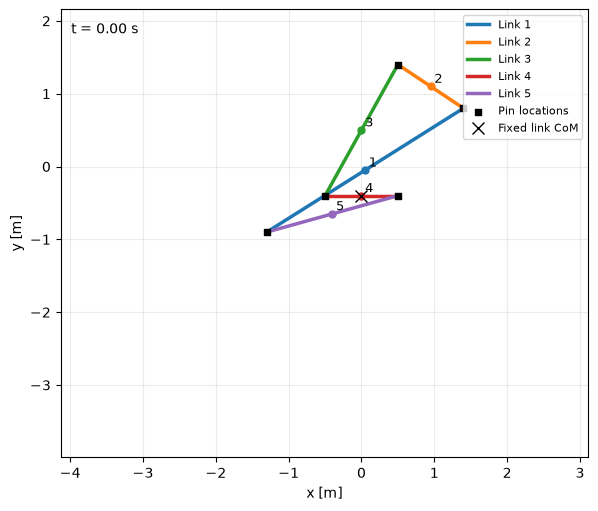

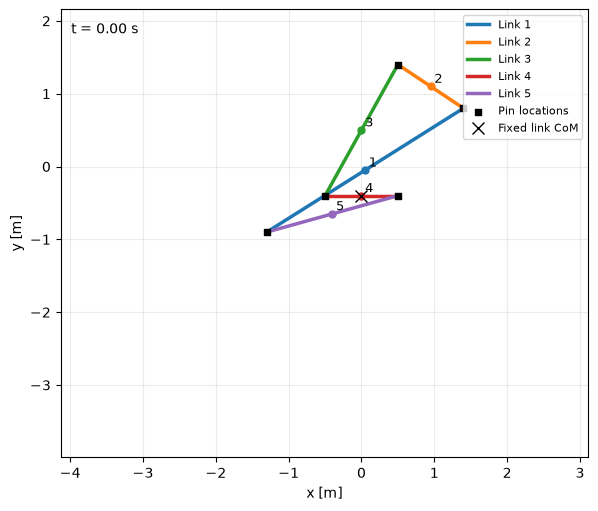

In [109]:
movie_fig, movie_ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
body_lines = []
center_markers = []
body_labels = []
for body in range(body_count):
    line, = movie_ax.plot([], [], color=f'C{body}', linewidth=2.5, label=f'Link {body + 1}')
    marker, = movie_ax.plot([], [], marker='o', linestyle='None', color=f'C{body}', markersize=5)
    body_lines.append(line)
    center_markers.append(marker)
    body_labels.append(movie_ax.text(0.0, 0.0, str(body + 1), fontsize=9))
pin_marker = movie_ax.scatter([], [], marker='s', color='black', s=22, label='Pin locations', zorder=4)
time_label = movie_ax.text(0.02, 0.97, '', transform=movie_ax.transAxes, va='top')
fixed_marker, = movie_ax.plot([], [], marker='x', linestyle='None', color='black',
                              markersize=9, label='Fixed link CoM')
movie_ax.set_xlim(*x_limits)
movie_ax.set_ylim(*y_limits)
movie_ax.set_aspect('equal', adjustable='box')
movie_ax.set_xlabel('x [m]')
movie_ax.set_ylabel('y [m]')
movie_ax.grid(True, alpha=0.25)
movie_ax.legend(loc='upper right', fontsize=8)


def update_movie(frame_number):
    sample_index = frame_indices[frame_number]
    q = solution.y[:coordinate_count, sample_index]
    pose = q.reshape(body_count, 3)
    for body in range(body_count):
        center = pose[body, :2]
        points = body_attachment_points(system, q, body)
        order = np.argsort(np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0]))
        outline = points[order]
        if len(outline) > 2:
            outline = np.vstack((outline, outline[0]))

        # Update existing Matplotlib artists instead of rebuilding the plot each frame.
        body_lines[body].set_data(outline[:, 0], outline[:, 1])
        center_markers[body].set_data([center[0]], [center[1]])
        body_labels[body].set_position((center[0] + 0.05, center[1] + 0.05))
    pin_marker.set_offsets(joint_positions_at(q))
    fixed_marker.set_data([q[9]], [q[10]])
    time_label.set_text(f't = {solution.t[sample_index]:.2f} s')
    return (*body_lines, *center_markers, *body_labels, pin_marker, fixed_marker, time_label)


# Draw frame zero for a useful preview before writing the animation file.
update_movie(0)
display(movie_fig)

### Write and verify the movie

At 20 fps, a ten-second GIF needs 200 frames. Each frame uses one saved solution state. The final checks reopen the file and inspect its encoded frame count and total frame duration instead of assuming that a successful `save` call means the requested duration was written.

Saved: C:\Users\Mourad\Desktop\multybody systems\constrained_five_link_10s.gif
Duration: 10.00 s | Frames: 200 | FPS: 20 | Size: 1,246,124 bytes


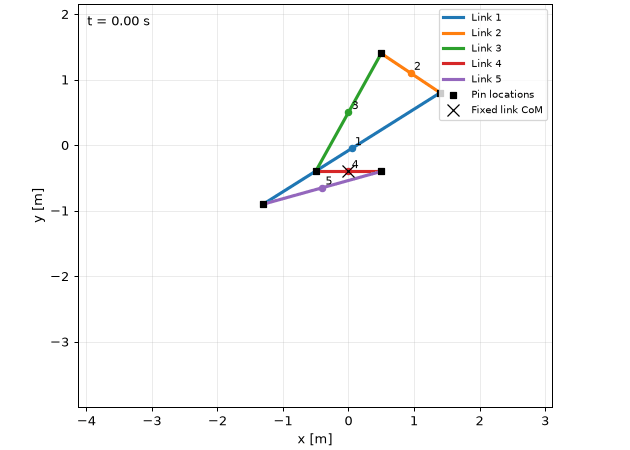

In [110]:
# FuncAnimation calls update_movie for each sampled trajectory state.
movie = FuncAnimation(
    movie_fig,
    update_movie,
    frames=frame_count,
    interval=1000 / fps,
    repeat=False,
    blit=False,
)
movie_path = Path.cwd() / 'constrained_five_link_10s.gif'

# PillowWriter encodes the requested frame rate into the animated GIF.
movie.save(movie_path, writer=PillowWriter(fps=fps), dpi=90)
plt.close(movie_fig)

# Reopen the artifact and verify its actual encoded duration and number of frames.
with PILImage.open(movie_path) as saved_movie:
    saved_frames = saved_movie.n_frames
    duration_ms = sum(
        saved_movie.seek(index) or saved_movie.info.get('duration', 0)
        for index in range(saved_frames)
    )
assert saved_frames == frame_count
assert duration_ms == int(movie_duration * 1000)
print(f'Saved: {movie_path.resolve()}')
print(f'Duration: {duration_ms / 1000:.2f} s | Frames: {saved_frames} | FPS: {fps} | Size: {movie_path.stat().st_size:,} bytes')
display(NotebookImage(filename=str(movie_path)))